In [ ]:
#iniciando a importação da base de dados que desejo trabalhar - quais tipos de dados estou lidando?
import pandas as pd
dados = pd.read_csv('base_clientes_banco.csv')

In [ ]:
dados.head()


,id_cliente,nome_cliente,idade,estado_civil,tem_dependentes,renda_mensal,pontuacao_score,meses_de_relacionamento,categoria_cartao,saldo_investimentos,contratou_seguro_vida
0,ID_100000,Brenda Alves,56,Solteiro(a),0,3495.61,830,236,Internacional,0.00,0
1,ID_100001,Sra. Isabelly Câmara,69,Solteiro(a),0,4709.70,405,101,Gold,1244.51,0
2,ID_100002,Cauã Rocha,46,Casado(a),1,2020.82,781,46,Internacional,0.00,1
3,ID_100003,Dra. Aurora Pastor,32,Divorciado(a),0,3718.76,505,80,Internacional,0.00,0
4,ID_100004,Ana Beatriz Alves,60,Solteiro(a),1,2059.56,546,107,Não Possui,1471.95,0


In [ ]:
#iniciando processo de data cleaning com retirada de dados nulos da base
dados.isnull().sum()

,0
id_cliente,0
nome_cliente,0
idade,0
estado_civil,0
tem_dependentes,0
renda_mensal,0
pontuacao_score,0
meses_de_relacionamento,0
categoria_cartao,0
saldo_investimentos,0


In [ ]:
#neste caso não há dados nulos, mas se houvessem dados nulos, poderiamos regularizar assim:
dados = dados.dropna()

In [ ]:
dados.shape

(5000, 11)

In [ ]:
#verificação de tipo de dados em cada coluna
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_cliente               5000 non-null   object 
 1   nome_cliente             5000 non-null   object 
 2   idade                    5000 non-null   int64  
 3   estado_civil             5000 non-null   object 
 4   tem_dependentes          5000 non-null   int64  
 5   renda_mensal             5000 non-null   float64
 6   pontuacao_score          5000 non-null   int64  
 7   meses_de_relacionamento  5000 non-null   int64  
 8   categoria_cartao         5000 non-null   object 
 9   saldo_investimentos      5000 non-null   float64
 10  contratou_seguro_vida    5000 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 429.8+ KB


In [ ]:
#tipos de dados estão compatíveis com o que precisamos
#agora vamos eliminar colunas que não são tão importantes para o nosso estudo de caso
#neste caso as colunas de ID e de nome são dispensáveis pois queremos padroes grupais

dados = dados.drop(columns=['id_cliente','nome_cliente'])

In [ ]:
dados.head()

,idade,estado_civil,tem_dependentes,renda_mensal,pontuacao_score,meses_de_relacionamento,categoria_cartao,saldo_investimentos,contratou_seguro_vida
0,56,Solteiro(a),0,3495.61,830,236,Internacional,0.00,0
1,69,Solteiro(a),0,4709.70,405,101,Gold,1244.51,0
2,46,Casado(a),1,2020.82,781,46,Internacional,0.00,1
3,32,Divorciado(a),0,3718.76,505,80,Internacional,0.00,0
4,60,Solteiro(a),1,2059.56,546,107,Não Possui,1471.95,0


In [ ]:
#agora vamos agrupar os clientes que contrataram e os que não contrataram
dados.groupby('contratou_seguro_vida').mean(numeric_only=True)

,idade,tem_dependentes,renda_mensal,pontuacao_score,meses_de_relacionamento,saldo_investimentos
contratou_seguro_vida,,,,,,
0,46.474824,0.592941,3953.971118,639.590118,118.317176,2473.525162
1,44.300000,0.992000,5180.104947,720.901333,117.480000,5831.561547


In [ ]:
#vamos tratar essa tabela para melhorar a visualização e arredondar dados com muitas casas decimais
resumo_perfil = dados.groupby('contratou_seguro_vida').mean(numeric_only=True).T.round(2)

In [ ]:
resumo_perfil.columns = ['Não Contratou (0)','Contratou (1)']
resumo_perfil

,Não Contratou (0),Contratou (1)
idade,46.47,44.30
tem_dependentes,0.59,0.99
renda_mensal,3953.97,5180.10
pontuacao_score,639.59,720.90
meses_de_relacionamento,118.32,117.48
saldo_investimentos,2473.53,5831.56


In [ ]:
# Criamos uma cópia do resumo para não estragar os dados originais
resumo_formatado = resumo_perfil.copy()

# Formatando cada linha de um jeito amigável para o gerente de carteira
formatacoes = {
    'idade': '{:.0f} anos',
    'tem_dependentes': '{:.1%}',
    'renda_mensal': 'R$ {:.2f}',
    'pontuacao_score': '{:.0f} pts',
    'meses_de_relacionamento': '{:.0f} meses',
    'saldo_investimentos': 'R$ {:.2f}'
}

# Aplicando a formatação na tabela
for linha, formato in formatacoes.items():
    if linha in resumo_formatado.index:
        resumo_formatado.loc[linha] = resumo_formatado.loc[linha].apply(lambda x: formato.format(x))

resumo_formatado

/tmp/ipykernel_1911/1086253718.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '46 anos' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  resumo_formatado.loc[linha] = resumo_formatado.loc[linha].apply(lambda x: formato.format(x))
/tmp/ipykernel_1911/1086253718.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '44 anos' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  resumo_formatado.loc[linha] = resumo_formatado.loc[linha].apply(lambda x: formato.format(x))


,Não Contratou (0),Contratou (1)
idade,46 anos,44 anos
tem_dependentes,59.0%,99.0%
renda_mensal,R$ 3953.97,R$ 5180.10
pontuacao_score,640 pts,721 pts
meses_de_relacionamento,118 meses,117 meses
saldo_investimentos,R$ 2473.53,R$ 5831.56


In [ ]:
#foco no que importa! Meses de relacionamento não impacta no perfil neste caso - vamos retirar!
dados = dados.drop(columns=['meses_de_relacionamento'])

In [ ]:
dados.columns

Index(['idade', 'estado_civil', 'tem_dependentes', 'renda_mensal',
       'pontuacao_score', 'categoria_cartao', 'saldo_investimentos',
       'contratou_seguro_vida'],
      dtype='object')

In [ ]:
#média etaria é muito parecida, queremos entender melhor qual faixa tem uma maior aceitação

In [ ]:
# Definir os limites das idades para cada categoria com o pandas pd.cut
limites = [17, 30, 45, 60, 75]
nomes_faixas = ['18-30 anos', '31-45 anos', '46-60 anos', '61-75 anos']

# Aqui achei interessante criar a nova coluna baseada nas faixas etárias
dados['faixa_etaria'] = pd.cut(dados['idade'], bins=limites, labels=nomes_faixas)

# Depois interessante cruzar a nova faixa etária com quem contratou o seguro (em porcentagem)
pd.crosstab(dados['faixa_etaria'], dados['contratou_seguro_vida'], normalize='index') * 100

contratou_seguro_vida,0,1
faixa_etaria,,
18-30 anos,94.708520,5.291480
31-45 anos,72.432024,27.567976
46-60 anos,80.015198,19.984802
61-75 anos,94.939759,5.060241


In [ ]:
# notamos que duas faixas etárias sobressaem nessa regra de negócio. Vamos filtrar para afunilar o publico alvo
dados = dados[(dados['idade'] >= 31) & (dados['idade'] <= 60)]

dados.shape

(2640, 9)

/tmp/ipykernel_1911/1102219429.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dados, x='contratou_seguro_vida', y='renda_mensal', ax=axes[0], palette='Blues')
/tmp/ipykernel_1911/1102219429.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dados, x='contratou_seguro_vida', y='tem_dependentes', ax=axes[1], palette='Oranges_r', errorbar=None)


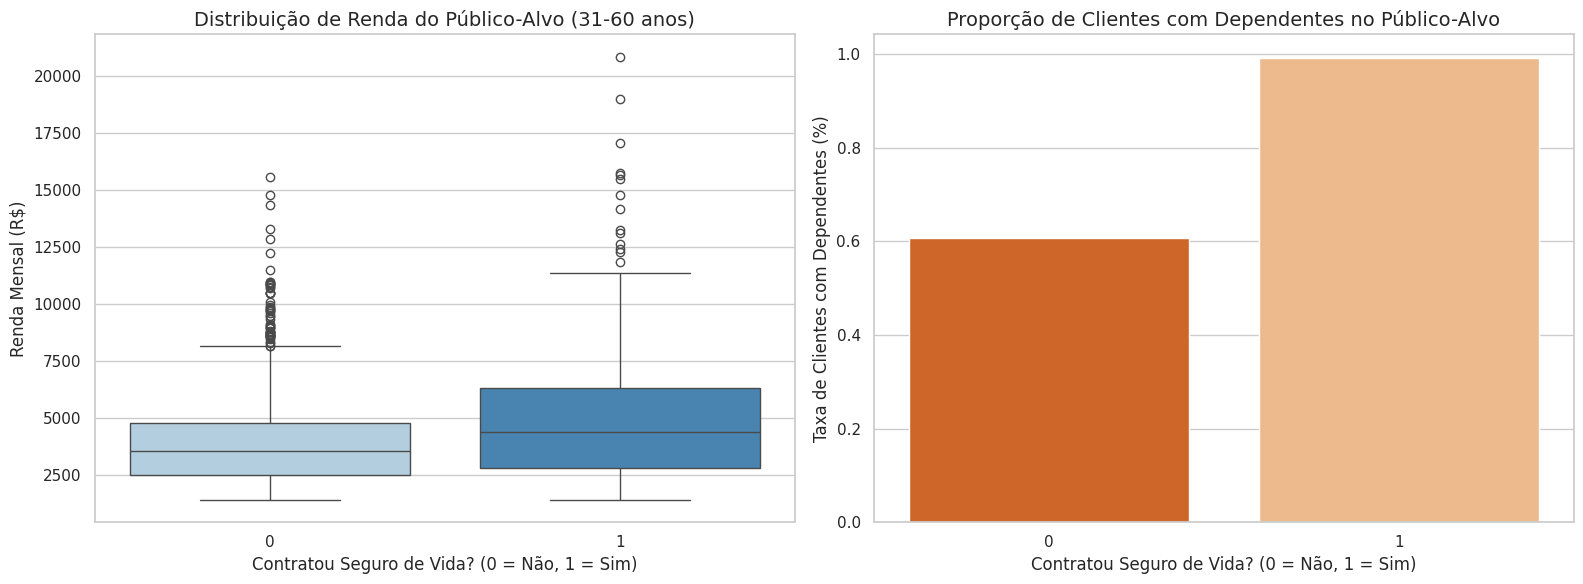

In [ ]:
#limpeza de dados feita, agora é hora de demonstrar a ANÁLISE EXPLORATÓRIA dos dados.
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o visual dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Caixa de Renda (Boxplot) para o público de 31 a 60 anos
sns.boxplot(data=dados, x='contratou_seguro_vida', y='renda_mensal', ax=axes[0], palette='Blues')
axes[0].set_title('Distribuição de Renda do Público-Alvo (31-60 anos)', fontsize=14)
axes[0].set_xlabel('Contratou Seguro de Vida? (0 = Não, 1 = Sim)', fontsize=12)
axes[0].set_ylabel('Renda Mensal (R$)', fontsize=12)

# Gráfico 2: Taxa de Dependentes para o público de 31 a 60 anos
sns.barplot(data=dados, x='contratou_seguro_vida', y='tem_dependentes', ax=axes[1], palette='Oranges_r', errorbar=None)
axes[1].set_title('Proporção de Clientes com Dependentes no Público-Alvo', fontsize=14)
axes[1].set_xlabel('Contratou Seguro de Vida? (0 = Não, 1 = Sim)', fontsize=12)
axes[1].set_ylabel('Taxa de Clientes com Dependentes (%)', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
#RESULTADO DESSA ANÁLISE: CLIENTES COM DEPENDENTES, ENTRE 31 E 60 ANOS, COM RENDA MAIOR DE 5.000,00 SÃO O PUBLICO ALVO

In [ ]:
#hora de dividir a base de dados entre TREINO E TESTE
#para o algoritmo entender alguns dados que estao em texto, vamos transformar em colunas com dados binarios

In [ ]:
# Removemos a coluna de faixa etária que usamos apenas para os gráficos pois não será usada aqui
dados = dados.drop(columns=['faixa_etaria'])

# transformação dos dados de texto em numéricos - FALSE 0 E TRUE 1 (dummies)
dados_preparados = pd.get_dummies(dados, columns=['estado_civil', 'categoria_cartao'], dtype=int)

dados_preparados.head()

,idade,tem_dependentes,renda_mensal,pontuacao_score,saldo_investimentos,contratou_seguro_vida,estado_civil_Casado(a),estado_civil_Divorciado(a),estado_civil_Solteiro(a),estado_civil_Viúvo(a),categoria_cartao_Black,categoria_cartao_Gold,categoria_cartao_Internacional,categoria_cartao_Não Possui
0,56,0,3495.61,830,0.00,0,0,0,1,0,0,0,1,0
2,46,1,2020.82,781,0.00,1,1,0,0,0,0,0,1,0
3,32,0,3718.76,505,0.00,0,0,1,0,0,0,0,1,0
4,60,1,2059.56,546,1471.95,0,0,0,1,0,0,0,0,1
6,38,1,5030.32,388,45450.75,0,0,0,1,0,0,0,1,0


In [ ]:
#hora de separar TREINO E TESTE
#X contém todas as colunas, EXCETO a nossa variável alvo que seria do seguro de vida
X = dados_preparados.drop(columns=['contratou_seguro_vida'])

# y contém APENAS a coluna que queremos prever - a retirada da base x
y = dados_preparados['contratou_seguro_vida']

# Verificar o tamanho de cada um
print("Formato das características (X):", X.shape)
print("Formato do alvo (y):", y.shape)

Formato das características (X): (2640, 13)
Formato do alvo (y): (2640,)


In [ ]:
from sklearn.model_selection import train_test_split

#Achei interessante divisao de 20% e 80%
X_treino, X_test, y_treino, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Conferindo os tamanhos das novas bases
print("Base de Treino (Perguntas):", X_treino.shape)
print("Base de Teste (Perguntas):", X_test.shape)
print("Respostas de Treino:", y_treino.shape)
print("Respostas de Teste:", y_test.shape)

Base de Treino (Perguntas): (2112, 13)
Base de Teste (Perguntas): (528, 13)
Respostas de Treino: (2112,)
Respostas de Teste: (528,)


In [ ]:
#REGRESSÃO LOGÍSTICA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 1. Padronizar os dados (Colocar Idade, Renda, Score na mesma escala)
scaler = StandardScaler()
X_treino_padrao = scaler.fit_transform(X_treino)
X_test_padrao = scaler.transform(X_test)

# 2. Instanciar e Treinar a Regressão Logística
modelo_logistico = LogisticRegression(random_state=42)
modelo_logistico.fit(X_treino_padrao, y_treino)

# 3. Testar o modelo nas 528 linhas misteriosas
previsoes_logistica = modelo_logistico.predict(X_test_padrao)

# 4. Calcular a Acurácia Final
acuracia_log = accuracy_score(y_test, previsoes_logistica)

print(f"Modelo Treinado com Sucesso!")
print(f"Acurácia da Regressão Logística no Teste: {acuracia_log * 100:.2f}%")

Modelo Treinado com Sucesso!
Acurácia da Regressão Logística no Teste: 82.39%


/tmp/ipykernel_1911/2935075545.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_pesos, x='Peso', y='Característica', palette='vlag')


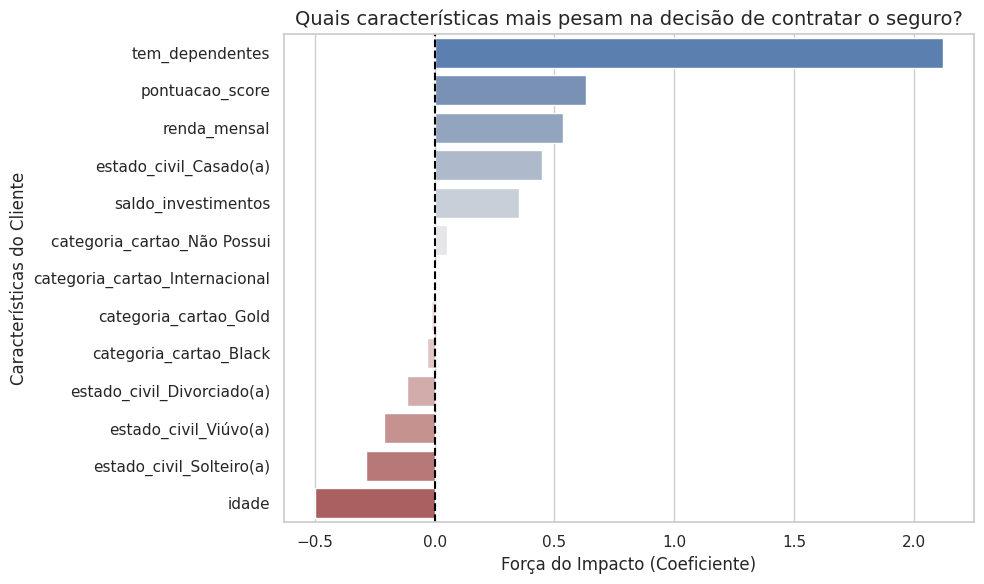

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extraindo os coeficientes (pesos) que o modelo deu para cada variável
importancias = modelo_logistico.coef_[0]
colunas = X.columns

# Criando um DataFrame para organizar os pesos
df_pesos = pd.DataFrame({'Característica': colunas, 'Peso': importancias})
df_pesos = df_pesos.sort_values(by='Peso', ascending=False)

# Criando o gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(data=df_pesos, x='Peso', y='Característica', palette='vlag')
plt.title('Quais características mais pesam na decisão de contratar o seguro?', fontsize=14)
plt.xlabel('Força do Impacto (Coeficiente)', fontsize=12)
plt.ylabel('Características do Cliente', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--') # Linha central no zero
plt.tight_layout()
plt.show()

In [ ]:
# 1. Padronizar a base inteira (X) usando o mesmo scaler que treinamos
X_completo_padrao = scaler.transform(X)

# 2. Calcular a probabilidade de cada cliente
probabilidades = modelo_logistico.predict_proba(X_completo_padrao)[:, 1]

# 3. Criar o relatório final a partir da base original
relatorio_gerente = dados.copy()

# 4. Criar um "Código do Cliente" baseado no índice para o gerente conseguir se localizar
# Ex: Cliente 0, Cliente 1, Cliente 2...
relatorio_gerente['Código do Cliente'] = relatorio_gerente.index

# 5. Adicionar a coluna de probabilidade calculada pelo modelo
relatorio_gerente['Chance_de_Contratar (%)'] = (probabilidades * 100).round(2)

# 6. O FILTRO CRUCIAL: Manter no relatório APENAS quem ainda NÃO tem seguro (valor igual a 0)
relatorio_gerente = relatorio_gerente[relatorio_gerente['contratou_seguro_vida'] == 0]

# 7. Organizar as colunas para que o Código e a Chance fiquem logo no começo
colunas_ordenadas = ['Código do Cliente', 'Chance_de_Contratar (%)'] + [col for col in dados.columns]
relatorio_gerente = relatorio_gerente[colunas_ordenadas]

# 8. Ordenar do cliente com maior chance para o de menor chance
relatorio_gerente = relatorio_gerente.sort_values(by='Chance_de_Contratar (%)', ascending=False)

# 9. Salvar no arquivo Excel focado em prospecção
relatorio_gerente.to_excel('lista_prospeccao_seguro.xlsx', index=False)

print(f"Sucesso! Gerada lista com {len(relatorio_gerente)} clientes prontos para prospecção.")

from google.colab import files
files.download('lista_prospeccao_seguro.xlsx')

Sucesso! Gerada lista com 2012 clientes prontos para prospecção.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>